[![Open In Colab](https://google.com)](https://google.comhamagami/IS2026/blob/main/06_Hierarchical_interactive.ipynb)

<a href="https://colab.research.google.com/github/hamagami/IS2026/blob/main/06_Hierarchical_interactive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 階層的クラスタリング: 結合と木の切断を操作 / Hierarchical clustering: interactive merging and tree cuts



## 操作 / How to interact
「結合回数」を進めて，点群のグループとデンドログラムを同期させます．「高さで切る」にすると，しきい値の変化を観察できます．single / complete / average / wardを比較してください．Wardはユークリッド距離に基づくクラスタ内平方和の増加を使います．木の高さの数値を，異なるlinkage間でそのまま同じ意味と解釈しないでください．

Advance Merges to synchronize groups in the scatter plot with the dendrogram. Select Height cut to explore distance thresholds. Compare single, complete, average, and Ward linkage. Ward uses the increase in within-cluster squared deviations under Euclidean distance. Heights from different linkage methods do not have identical interpretations.


## 準備 / Setup


In [ ]:
import sys,subprocess,importlib.util
for module,package in [('sklearn','scikit-learn'),('ipywidgets','ipywidgets')]:
    if importlib.util.find_spec(module) is None: subprocess.check_call([sys.executable,'-m','pip','install','-q',package])
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs,make_moons
from sklearn.preprocessing import StandardScaler
import ipywidgets as widgets
from IPython.display import display,clear_output
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError: pass
plt.rcParams.update({'figure.dpi':110,'font.size':11})
COLORS=np.array(['#ff8618','#8b38c5','#00a99d','#2476dc','#d53c64','#96852b'])
def dataset(kind='blobs',seed=7):
    if kind=='moons':return make_moons(n_samples=100,noise=.06,random_state=seed)[0]
    x,_=make_blobs(n_samples=100,centers=[[-2,2],[-2,-2],[2,0]],cluster_std=.65,random_state=seed)
    if kind=='stretched':x=x@np.array([[1.8,.7],[0,.35]])
    if kind=='different scales':x[:,0]*=100
    return x


# 日本語フォントを設定します． / Configure a Japanese font for bilingual figures.
if importlib.util.find_spec('japanize_matplotlib') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'japanize-matplotlib'])
import japanize_matplotlib
plt.rcParams['axes.unicode_minus'] = False


## モデル / Model


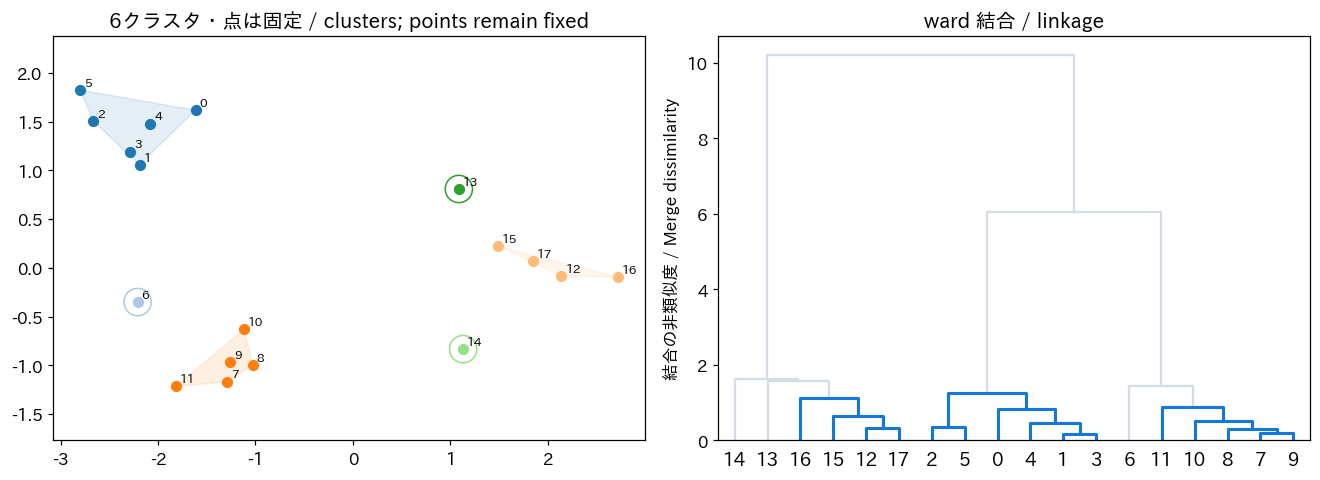

In [ ]:
from scipy.cluster.hierarchy import linkage,dendrogram,fcluster,cut_tree
from matplotlib.patches import Ellipse
from scipy.spatial import ConvexHull
rng=np.random.default_rng(17)
X=np.vstack([rng.normal([-2,1.5],.35,(6,2)),rng.normal([-1.5,-1],.35,(6,2)),rng.normal([2,0],.4,(6,2))])
def hierarchy_view(method='ward',merges=0,mode='Merge steps',height_fraction=.5):
    Z=linkage(X,method=method,metric='euclidean')
    if mode=='Height cut':
        height=float(height_fraction*Z[-1,2]);labels=fcluster(Z,t=height,criterion='distance')-1
    else:
        # cut_treeは「結合を何回終えたか」に対応する正確な群数を返します． / cut_tree gives the exact cluster count after the specified number of merges.
        labels=cut_tree(Z,n_clusters=[len(X)-merges]).ravel();height=None
    fig,axes=plt.subplots(1,2,figsize=(12,4.5))
    ax=axes[0]
    for j in np.unique(labels):
        pts=X[labels==j];color=plt.cm.tab20(int(j)%20)
        ax.scatter(*pts.T,color=color,s=40)
        if len(pts)==1:ax.add_patch(plt.Circle(pts[0],.14,fill=False,color=color))
        elif len(pts)==2:ax.plot(*pts.T,color=color,lw=6,alpha=.2)
        else:
            hull=ConvexHull(pts);poly=pts[hull.vertices];ax.fill(poly[:,0],poly[:,1],color=color,alpha=.12)
    for i,p in enumerate(X):ax.annotate(str(i),p+np.array([.04,.04]),fontsize=8)
    ax.set_title(f'{len(np.unique(labels))}クラスタ・点は固定 / clusters; points remain fixed');ax.set_aspect('equal',adjustable='datalim')
    # 完全な木を薄灰色にし，完了した結合だけを青で示します． / Draw the complete tree in light gray and completed merges in blue.
    d=dendrogram(Z,ax=axes[1],color_threshold=0,above_threshold_color='#d6dce5',labels=[str(i) for i in range(len(X))])
    if mode=='Merge steps':
        # dendrogramの内部ノード順は高さ順とは限らないため，merge高さで対応させます． / Match merges by height because dendrogram node order need not follow height order.
        completed=list(Z[:merges,2])
        for xs,ys in zip(d['icoord'],d['dcoord']):
            if any(np.isclose(max(ys),v) for v in completed):axes[1].plot(xs,ys,color='#1478d8',lw=2)
    else:axes[1].axhline(height,color='darkorange',ls='--',label=f'切断高さ / Cut={height:.2f}');axes[1].legend()
    axes[1].set_title(method+' 結合 / linkage');axes[1].set_ylabel('結合の非類似度 / Merge dissimilarity')
    plt.tight_layout();plt.show()
hierarchy_view(merges=12)


## インタラクティブ操作 / Interactive controls


In [ ]:
widgets.interact(hierarchy_view,
    method=widgets.Dropdown(options=[('単連結 / Single','single'),('完全連結 / Complete','complete'),('平均連結 / Average','average'),('ウォード / Ward','ward')],value='ward',description='結合方法 / Linkage', style={'description_width':'initial'}, layout=widgets.Layout(width='auto',min_width='260px')),
    merges=widgets.IntSlider(min=0,max=len(X)-1,value=0,description='結合回数 / Merges', style={'description_width':'initial'}, layout=widgets.Layout(width='auto',min_width='260px'),continuous_update=False),
    mode=widgets.Dropdown(options=[('結合を進める / Merge steps','Merge steps'),('高さで切る / Height cut','Height cut')],description='操作モード / Mode', style={'description_width':'initial'}, layout=widgets.Layout(width='auto',min_width='260px')),
    height_fraction=widgets.FloatSlider(min=0,max=1,step=.02,value=.5,description='切断高さ / Cut height', style={'description_width':'initial'}, layout=widgets.Layout(width='auto',min_width='260px'),continuous_update=False))


interactive(children=(Dropdown(description='結合方法 / Linkage', index=3, layout=Layout(min_width='260px', width='…

<function __main__.hierarchy_view(method='ward', merges=0, mode='Merge steps', height_fraction=0.5)>

## 試すこと / Things to try
- Mergesを0から17へ動かし，18クラスタが1クラスタになる過程を追う．
  Move Merges from 0 to 17 to follow 18 clusters merging into one.
- Height cutでは低い切断位置と高い切断位置を比べる．
  In Height cut mode, compare low and high cut positions.
- linkageを変え，結合順序と木の高さが変わることを確認する．
  Change the linkage method and observe changes in merge order and tree heights.
- ウィジェットが表示されないときは `hierarchy_view('average',12)` 等を直接実行できます．
  If widgets are unavailable, call a function such as `hierarchy_view('average',12)` directly.


## 参考 / References
- [SciPy linkage](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html)
